In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

<h1>3.97</h1>

<h2>a.</h2>

In [2]:

A = np.array([[-2,-1,1,2],
              [2,.5,.5,2],
              [-4/3,-1/6,1/6,4/3],
              [2/3,1/24,1/24,2/3]])
b = np.array([1,0,0,0])
sol = np.linalg.solve(A,b)
print(sol)
print("Expansion is true, and the order is 4")

[ 0.08333333 -0.66666667  0.66666667 -0.08333333]
Expansion is true, and the order is 4


<h2>b.</h2>

In [3]:
A = np.array([[1,1,1],
              [0,1,2],
              [0,.5,2]])
b = np.array([0,1,0])
sol = np.linalg.solve(A,b)
print(sol)
print("Expansion is true, and the order is 2")

[-1.5  2.  -0.5]
Expansion is true, and the order is 2


<h2>c.</h2>

In [4]:
A = np.array([[1,1,1,1,1],
              [-2,-1,0,1,2],
              [2,.5,0,.5,2],
              [-4/3,-1/6,0,1/6,4/3],
              [2/3,1/24,0,1/24,2/3]])
b = np.array([0,0,1,0,0])
sol = np.linalg.solve(A,b)
print(sol)
print("Expansion is true, and the order is 4")

[-0.08333333  1.33333333 -2.5         1.33333333 -0.08333333]
Expansion is true, and the order is 4


<h2>d.</h2>

In [5]:
A = np.array([[-2,-1,1,2],
              [2,.5,.5,2],
              [-4/3,-1/6,1/6,4/3],
              [2/3,1/24,1/24,2/3]])
b = np.array([0,0,1,0])
sol = np.linalg.solve(A,b)
print(sol)
print("Expansion is correct, and the order is 2")

[-0.5  1.  -1.   0.5]
Expansion is correct, and the order is 2


<h1>3.101</h1>

<h2>a.</h2>

In [6]:
data = np.array(pd.read_csv('../data/Exercise3_waterflow.csv'))
# Exercise3_waterflow.csv (local copy of the course dataset)
#print(data.T)

time = np.array([0,  7,  19,  25,  38,  47,  55])
flow_rate = np.array([316, 309, 296, 298, 305, 314, 322])
time_sec = time*60


# Use trapezoidal rule
area = np.sum((flow_rate[:-1] + flow_rate[1:]) * (time_sec[1:] - time_sec[:-1]) / 2)

print(f"By applying the trapezoidal rule, the total amount of water is {area} gallons")


#plt.plot(time_sec, flow_rate, ".")
#plt.fill_between(time_sec, flow_rate, alpha = 0.5)

By applying the trapezoidal rule, the total amount of water is 1010910.0 gallons


<h2>b.</h2>

In [7]:
def trapezoidal(f, a, b, n):
    width = (b-a)/n
    
    x = np.arange(a, b, width)
    
    y = f(x) 
    
    area = (y[0] + 2*np.sum(y[1:-1]) + y[-1]) * width / 2 
    
    return area 


def f(t):
    return 22.8 / (3.5 + 7*(t-1.25)**4)


a = 0
b = 2 
n = 100000 # higher n leads to a more accurate result

import scipy.integrate 

exact = scipy.integrate.quad(lambda t: 22.8 / (3.5 + 7*(t-1.25)**4), 0, 2)


approx = trapezoidal(f, a, b, n) * 60 # f(t) is measured in minutes, convert hour result to cars per minute

error = np.abs(exact[0]*60 - approx)/(exact[0]*60)

print(approx, error)
print(f"Total number of cars that cross the bridge is {approx:.0f} per minute with an error of {error} compared to the exact value, which is less than 0.05 with the n value of 100000. \nThe percentage error decreases with larger n and by applying a sufficiently large n value, we can ensure that our estimate has an error less than 5%.")


599.5064732554049 7.985928059469855e-06
Total number of cars that cross the bridge is 600 per minute with an error of 7.985928059469855e-06 compared to the exact value, which is less than 0.05 with the n value of 100000. 
The percentage error decreases with larger n and by applying a sufficiently large n value, we can ensure that our estimate has an error less than 5%.


<h1>3.103</h1>

a and b is using the same dataset but different appropriate variables.

'https://catalog.data.gov/dataset/water-quality-data-41c5e'

In [8]:
local_file_path = '../data/Water_Quality_Data.csv'
water_quality = pd.read_csv(local_file_path)

print(water_quality.columns.tolist())

['Site_Id', 'Unit_Id', 'Read_Date', 'Salinity (ppt)', 'Dissolved Oxygen (mg/L)', 'pH (standard units)', 'Secchi Depth (m)', 'Water Depth (m)', 'Water Temp (?C)', 'Air Temp-Celsius', 'Air Temp (?F)', 'Time (24:00)', 'Field_Tech', 'DateVerified', 'WhoVerified', 'AirTemp (C)', 'Year']


<h2>a.</h2> Derivative: (Air Temp (F) v.s. Water Temp (C)), see how water temperature, f(x), changes with air depth, x</br>

1. Remove all rows with missing values (nan) for air and water temperatures, and then apply Savitzky-Golay. filter to both variables to smooth them. After smoothing, the real data point plot is shown below (blue for original and orange for smoothed ones).</br>
2. Use NumPy function to find the derivative (in red).</br>


3. The derivative line indicates how the rate of changes in water temperature varies with changes in air temperature (C/F), where the derivative is steep, water temperature changes significantly with a small change in air temperature, indicating high sensitivity. Where the derivative is close to zero, water temperature changes little with changes in air temperature, indicating low sensitivity. This derivative helps understand the thermal dynamics in some environmental researches, particularly in understanding how air temperature fluctuations impact aquatic ecosystems.</br>
4. A "divide by zero" warning occurred during the calculation, suggesting that some consecutive smoothed air temperatures are very close to each other, resulting in a near-zero dx. This can lead to infinite or undefined derivative values. 

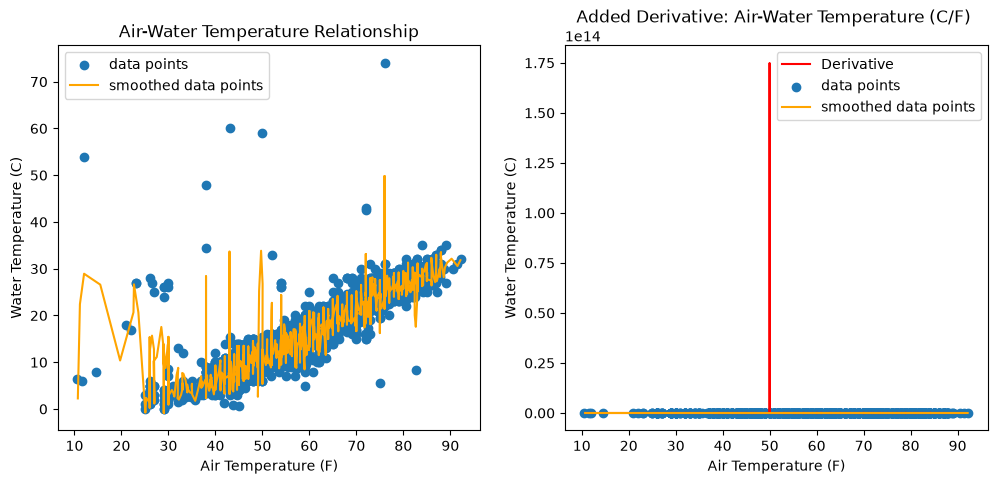

In [9]:
water_quality_a = water_quality.sort_values("Air Temp (?F)")
water_quality_a = water_quality_a.dropna(subset = ['Air Temp (?F)', 'Water Temp (?C)'])

air_temp = water_quality_a['Air Temp (?F)'].values
water_temp = water_quality_a['Water Temp (?C)'].values

from scipy.signal import savgol_filter

smoothed_air_temp = savgol_filter(air_temp, window_length = 5, polyorder = 3, mode = "nearest")
smoothed_water_temp = savgol_filter(water_temp, window_length = 5, polyorder = 3, mode = "nearest")


coefficients_air_water = np.polyfit(air_temp, water_temp, deg=3)
polynomial_model_air_water = np.poly1d(coefficients_air_water)


# plot
fig, axs = plt.subplots(1, 2, figsize = (12, 5))

axs[0].scatter(air_temp, water_temp, label="data points")
axs[0].plot(smoothed_air_temp, smoothed_water_temp, label="smoothed data points", color = "orange")
axs[0].set_xlabel("Air Temperature (F)")
axs[0].set_ylabel("Water Temperature (C)")
axs[0].set_title("Air-Water Temperature Relationship")
axs[0].legend()


# Comparing derivative with original points and smoothed ones
x = smoothed_air_temp # are nor uniformly spaced
y = smoothed_water_temp
dx = np.diff(x) # difference between each consecutive air temperature value
df = np.diff(y)/dx
axs[1].plot(x[:-1], df, label = "Derivative", color = "red")

axs[1].scatter(air_temp, water_temp, label="data points")
axs[1].plot(smoothed_air_temp, smoothed_water_temp, label="smoothed data points", color = "orange")
axs[1].set_xlabel("Air Temperature (F)")
axs[1].set_ylabel("Water Temperature (C)")
axs[1].set_title("Added Derivative: Air-Water Temperature (C/F) ")
axs[1].legend()

plt.show()


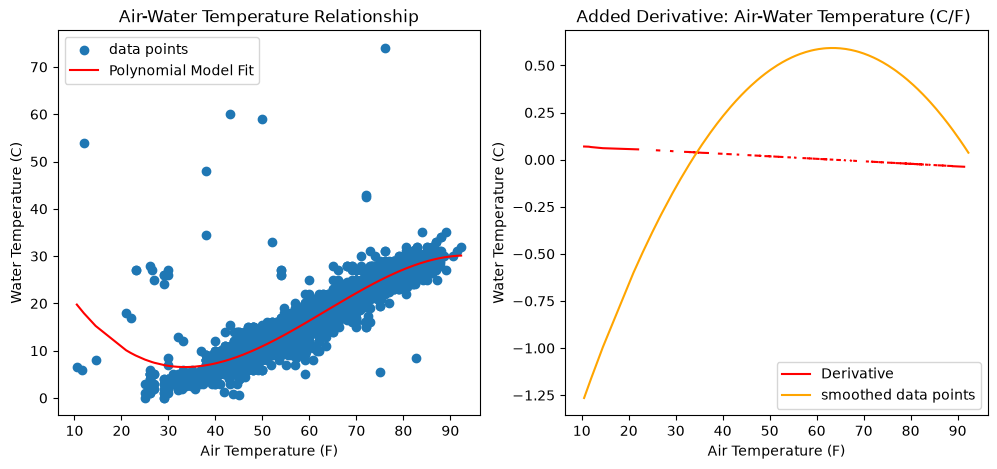

In [10]:
coefficients_air_water = np.polyfit(air_temp, water_temp, deg=3)
polynomial_model_air_water = np.poly1d(coefficients_air_water)
derivative_polynomial_model_air_water = polynomial_model_air_water.deriv()

# plot
fig, axs = plt.subplots(1, 2, figsize = (12, 5))

axs[0].scatter(air_temp, water_temp, label="data points")
axs[0].plot(air_temp, polynomial_model_air_water(air_temp), label='Polynomial Model Fit', color='red')
axs[0].set_xlabel("Air Temperature (F)")
axs[0].set_ylabel("Water Temperature (C)")
axs[0].set_title("Air-Water Temperature Relationship")
axs[0].legend()


# Comparing derivative with original points and smoothed ones
x = air_temp # are nor uniformly spaced
y = derivative_polynomial_model_air_water(air_temp)
dx = np.diff(x) # difference between each consecutive air temperature value
df = np.diff(y)/dx
axs[1].plot(x[:-1], df, label = "Derivative", color = "red")

axs[1].plot(x, y, label="smoothed data points", color = "orange")
axs[1].set_xlabel("Air Temperature (F)")
axs[1].set_ylabel("Water Temperature (C)")
axs[1].set_title("Added Derivative: Air-Water Temperature (C/F) ")
axs[1].legend()

plt.show()

['Site_Id', 'Unit_Id', 'Read_Date', 'Salinity (ppt)', 'Dissolved Oxygen (mg/L)', 'pH (standard units)', 'Secchi Depth (m)', 'Water Depth (m)', 'Water Temp (?C)', 'Air Temp-Celsius', 'Air Temp (?F)', 'Time (24:00)', 'Field_Tech', 'DateVerified', 'WhoVerified', 'AirTemp (C)', 'Year']
[-2.21428152e-04  4.21012181e-02 -2.07595408e+00  3.71645596e+01]


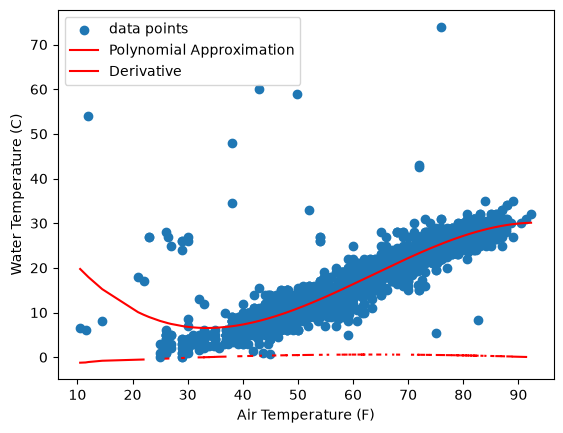

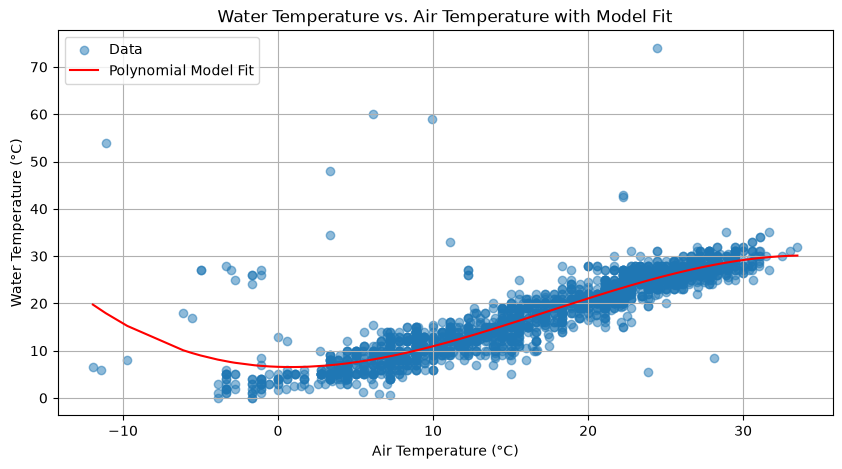

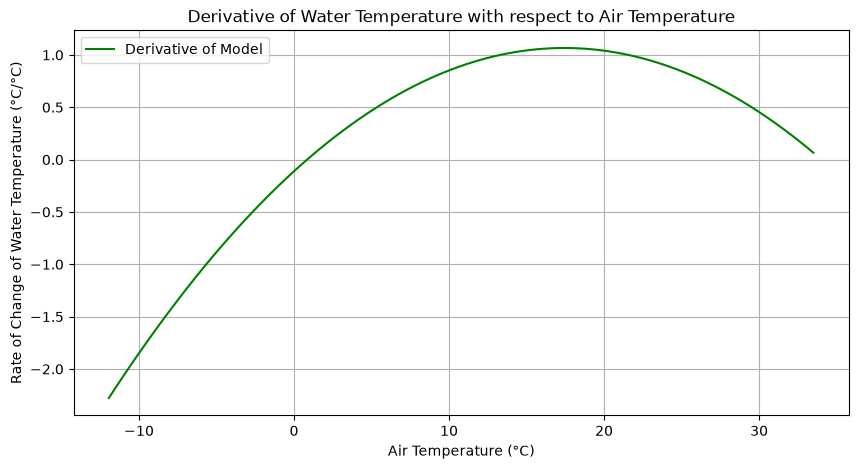

In [11]:
local_file_path = '../data/Water_Quality_Data.csv'
water_quality = pd.read_csv(local_file_path)

print(water_quality.columns.tolist())

coeff_air_water = np.polyfit(air_temp, water_temp , deg = 3)
print(coeff_air_water)
poly_model = np.poly1d(coeff_air_water)
approx_water_temp = poly_model(air_temp)

plt.scatter(air_temp, water_temp, label="data points")
plt.plot(air_temp, approx_water_temp, label = "Polynomial Approximation", color ="red")

x = air_temp
dx = np.diff(x)
y = approx_water_temp
df = np.diff(y)/dx
plt.plot(x[:-1], df, label = "Derivative", color = "red")

plt.xlabel("Air Temperature (F)")
plt.ylabel("Water Temperature (C)")
plt.legend()
plt.show()


# Reload the dataset
data = water_quality

# Convert 'Read_Date' to datetime and sort the data
data['Read_Date'] = pd.to_datetime(data['Read_Date'])
data.sort_values('Read_Date', inplace=True)

# Convert air temperature from Fahrenheit to Celsius for consistency in the analysis
data['Air Temp (C)'] = (data['Air Temp (?F)'] - 32) * (5/9)

# Drop missing temperature pairs before fitting (polyfit cannot handle NaN).
fit_data = data.dropna(subset=['Air Temp (C)', 'Water Temp (?C)'])

# Fit a polynomial model to the data (water temperature as a function of air temperature in Celsius)
coefficients_air_water = np.polyfit(fit_data['Air Temp (C)'], fit_data['Water Temp (?C)'], deg=3)
polynomial_model_air_water = np.poly1d(coefficients_air_water)

# Take the derivative of the polynomial model
derivative_polynomial_model_air_water = polynomial_model_air_water.deriv()

# Plotting the air temperature (in Celsius) against the water temperature with model fit
plt.figure(figsize=(10, 5))
plt.scatter(fit_data['Air Temp (C)'], fit_data['Water Temp (?C)'], label='Data', alpha=0.5)
x_sorted = np.sort(fit_data['Air Temp (C)'])
plt.plot(x_sorted, polynomial_model_air_water(x_sorted), label='Polynomial Model Fit', color='red')

plt.title('Water Temperature vs. Air Temperature with Model Fit')
plt.xlabel('Air Temperature (°C)')
plt.ylabel('Water Temperature (°C)')
plt.legend()
plt.grid(True)
plt.show()

# Plotting the derivative of the polynomial model
air_temp_celsius_range = np.linspace(fit_data['Air Temp (C)'].min(), fit_data['Air Temp (C)'].max(), 100)
plt.figure(figsize=(10, 5))
plt.plot(air_temp_celsius_range, derivative_polynomial_model_air_water(air_temp_celsius_range), label='Derivative of Model', color='green')

plt.title('Derivative of Water Temperature with respect to Air Temperature')
plt.xlabel('Air Temperature (°C)')
plt.ylabel('Rate of Change of Water Temperature (°C/°C)')
plt.legend()
plt.grid(True)
plt.show()


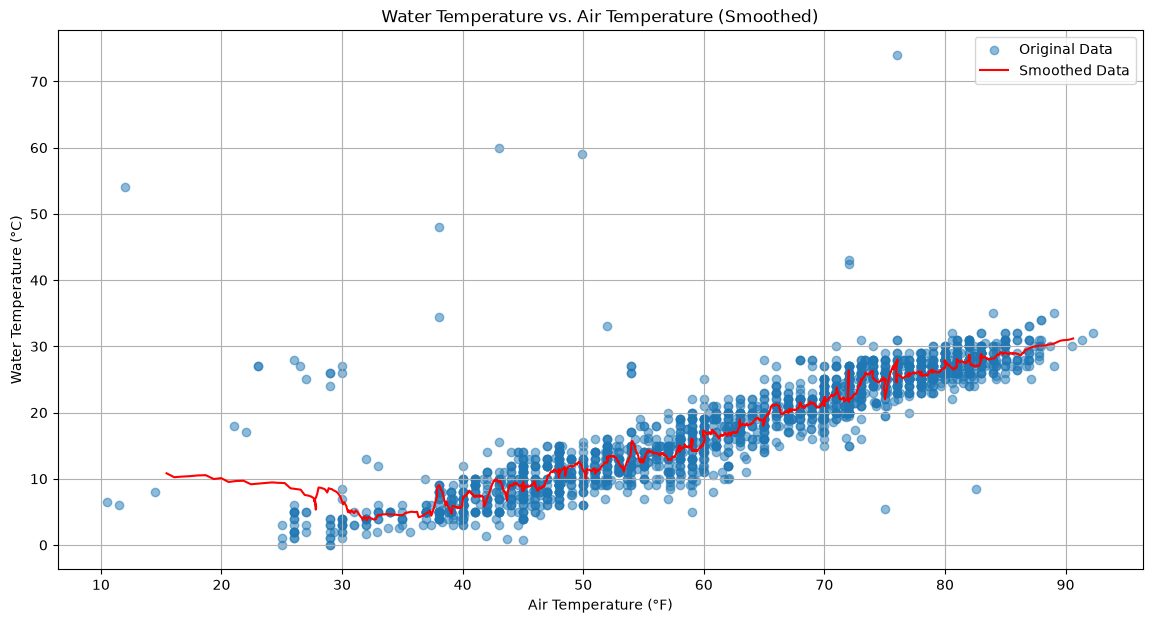

In [12]:
# Smooth both the water temperature and air temperature data using the Savitzky-Golay filter
smoothed_water_temp = savgol_filter(water_temp, window_length=51, polyorder=3, mode='nearest')
smoothed_air_temp = savgol_filter(air_temp, window_length=51, polyorder=3, mode='nearest')

# Convert the smoothed air temperature from Fahrenheit to Celsius for consistency in analysis
smoothed_air_temp_celsius = (smoothed_air_temp - 32) * (5/9)

# Plotting the original and smoothed data for comparison
plt.figure(figsize=(14, 7))

# Original data points
plt.scatter(air_temp, water_temp, alpha=0.5, label='Original Data')

# Smoothed data
plt.plot(smoothed_air_temp, smoothed_water_temp, label='Smoothed Data', color='red')

plt.xlabel('Air Temperature (°F)')
plt.ylabel('Water Temperature (°C)')
plt.title('Water Temperature vs. Air Temperature (Smoothed)')
plt.legend()
plt.grid(True)
plt.show()


<h2>b.</h2> Integral: water depth (m) as x, and dissolved oxygen (mg/L) as f(x)</br>

1. Applying a customized Trapezoidal Rule to evaluate the integral, the filled area in the second plot (in orange) represents the integral of dissolved oxygen concentration over water depth. This is the accumulated total volume of dissolved oxygen across the range of depths. </br>

2. Approximate value of integral is 55.05 in mg/L*m. If we consider the entire column of water from the shallowest to the deepest level measured, there would be approximate 55.08 mg oxygen for every liter of water across each meter of depth. This informs the oxygen concentration distribution in a water body. 

55.0814682582759


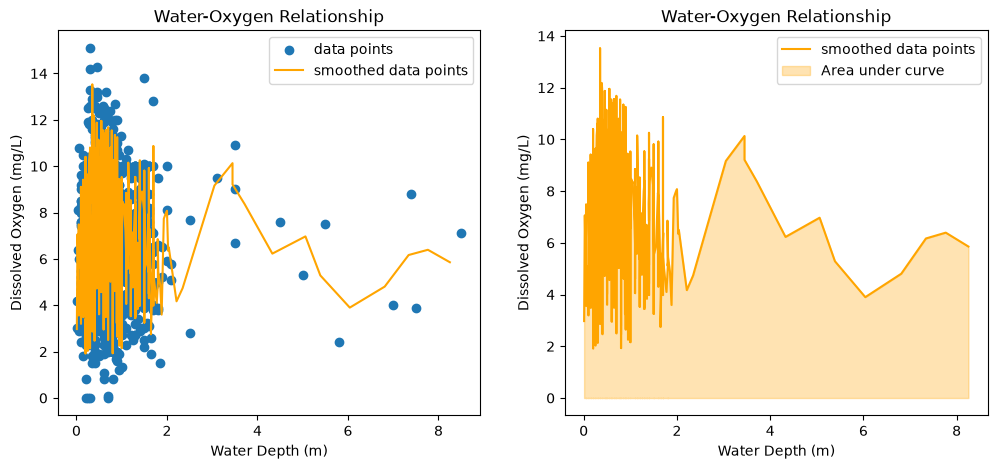

In [13]:
water_quality_b = water_quality.sort_values("Water Depth (m)")
water_quality_b = water_quality_b.dropna(subset = ['Water Depth (m)', 'Dissolved Oxygen (mg/L)'])

water_depth = water_quality_b['Water Depth (m)'].values
oxygen = water_quality_b['Dissolved Oxygen (mg/L)'].values


#smoothing all data points
smoothed_water_depth = savgol_filter(water_depth, window_length = 5, polyorder = 3, mode = "nearest")
smoothed_oxygen = savgol_filter(oxygen, window_length = 5, polyorder = 3, mode = "nearest")

# Apply trapezoidal rule to evaluate the integral
def trapezoidal(x, y, n):
    width = (x[-1] - x[0])/n
    area = (y[0] + 2*np.sum(y[1:-1]) + y[-1]) * width / 2
    return area 

x = smoothed_water_depth
y = smoothed_oxygen
approx_integral = trapezoidal(x, y, len(x)-1)
print(approx_integral)


# plot
fig, axs = plt.subplots(1, 2, figsize = (12, 5))

axs[0].scatter(water_depth, oxygen, label = "data points")
axs[0].plot(smoothed_water_depth, smoothed_oxygen, label="smoothed data points", color = "orange")
axs[0].set_xlabel("Water Depth (m)")
axs[0].set_ylabel("Dissolved Oxygen (mg/L)")
axs[0].set_title("Water-Oxygen Relationship")
axs[0].legend()

axs[1].plot(smoothed_water_depth, smoothed_oxygen, label="smoothed data points", color = "orange")
axs[1].fill_between(smoothed_water_depth, smoothed_oxygen, color = "orange", alpha = 0.3, label="Area under curve")
axs[1].set_xlabel("Water Depth (m)")
axs[1].set_ylabel("Dissolved Oxygen (mg/L)")
axs[1].set_title("Water-Oxygen Relationship")
axs[1].legend()

plt.show()

<h1>3.104</h1>

In [14]:
f = lambda x: x/(1+x**4)
g = lambda x: (x-1)**3 * (x-2)**2
h = lambda x: np.sin(x**2)

def trapezoidal(f, a, b, n):
    width = (b-a)/n
    x = np.linspace(a, b, n+1)
    y = f(x)    
    area = (y[0] + 2*np.sum(y[1:-1]) + y[-1]) * width / 2 # area of each trapezoid, first and last function values (y) are only used once
    return area 

a = -1
b = 2
n = 1000000

x = np.linspace(a, b, 400)

The integral is 0.2702097501355451 with an error of 9.36177602896211e-13, which is accurate to 10 decimal places with enough large n value of 1000000.


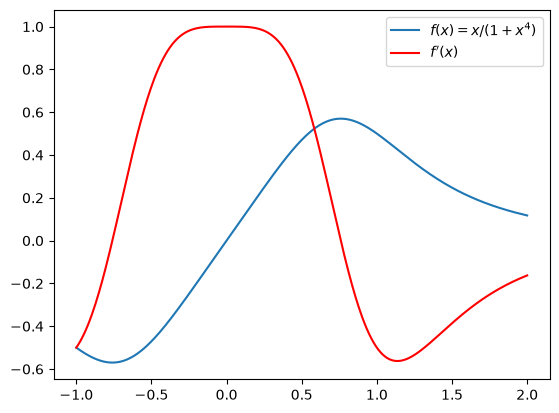

In [15]:
def F(x):
    return np.arctan(x**2)/2

exact_f = F(b) - F(a)
approx_f = trapezoidal(f, a, b, n)
error_f = (np.abs(exact_f - approx_f)/exact_f)

# Integral
print(f"The integral is {approx_f} with an error of {error_f}, which is accurate to 10 decimal places with enough large n value of {n}.")

# first derivative
# scipy.misc.derivative was removed in SciPy 1.12; use the same central differences.
def derivative(f, x, dx=1e-6, n=1):
    if n == 1:
        return (f(x + dx) - f(x - dx)) / (2 * dx)
    if n == 2:
        return (f(x + dx) - 2 * f(x) + f(x - dx)) / dx**2
    raise ValueError("only n=1 and n=2 are supported")


derivative_f = derivative(f, x, dx=1e-10)


# plot
plt.plot(x, f(x), label="$f(x) = x/(1+x^4)$")
plt.plot(x, derivative_f, color = "red", label ="$f'(x)$")
plt.legend()
plt.show()

The integral is -27.450000000117 with an error of -4.26235044021628e-12, which is accurate to 10 decimal places with enough large n value of 1000000.


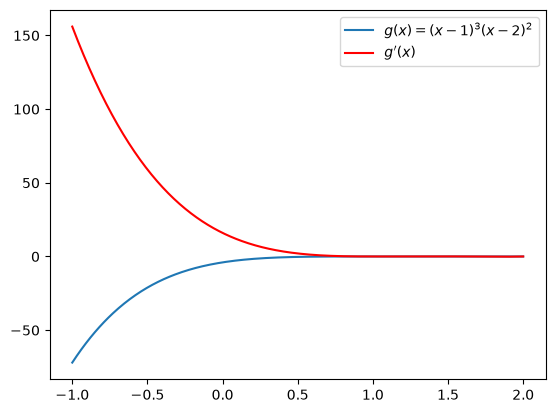

In [16]:
def G(x):
    return (x-1)**4 * (10*x**2 - 44*x + 49) / 60


exact_g = G(b) - G(a)
approx_g = trapezoidal(g, a, b, n)
error_g = (np.abs(exact_g - approx_g)/exact_g)

print(f"The integral is {approx_g} with an error of {error_g}, which is accurate to 10 decimal places with enough large n value of {n}.")


derivative_g = derivative(g, x, dx=1e-10)

plt.plot(x, g(x), label = "$g(x) = (x-1)^3(x-2)^2$")
plt.plot(x, derivative_g, color = "red", label ="$g'(x)$")
plt.legend()

The integral is 1.1150447910659866 with an error of 1.031918315694129e-12, which is accurate to 10 decimal places with enough large n value of 1000000.


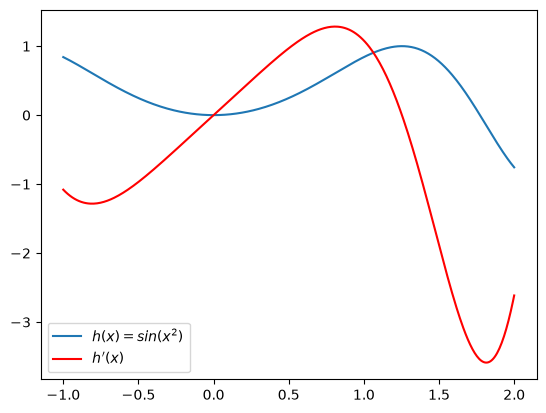

In [17]:
exact_h = scipy.integrate.quad(h, a, b)
approx_h = trapezoidal(h, a, b, n)
error_h = (np.abs(exact_h[0] - approx_h)/exact_h[0])


print(f"The integral is {approx_h} with an error of {error_h}, which is accurate to 10 decimal places with enough large n value of {n}.")

derivative_h = derivative(h, x, dx=1e-10)

plt.plot(x, h(x), label="$h(x) = sin(x^2)$")
plt.plot(x, derivative_h, label="$h'(x)$", color="red")
plt.legend()